# DAS azimuth posterior next to the three-seismometer combined azimuth

**(a)** The marginal posterior $p(\theta\,|\,\text{block})$ from
`scripts/bf_inv_disp/analyze_bf_disp_posterior.py`, re-gridded onto a strictly
regular 30-minute axis so gaps stay visible.

**(b)** The group-PCA azimuth of seismometers N2, N4 and N5 over the high-wind
windows ($U \geq$ `HIGH_WIND`, SWIFT19 drifter wind), as a function of
frequency, from `notebooks/seismometer/mainSwellDir_seism_Welch.ipynb`.

The PCA result is an *axis*, so every statistic is axial: the angles are
doubled, averaged as unit vectors, and halved back. Per sensor $i$ and
frequency bin, $\mu_i$ is the axial mean over that sensor's high-wind windows.
The combined azimuth is the equal-weight axial mean of the $K$ sensor means,

$$\bar\mu = \tfrac12 \arg \sum_{i=1}^{K} e^{\,\mathrm{i}\,2\mu_i},$$

equal weight per *sensor* rather than per window, so a sensor with more
surviving windows does not dominate. The band is $\pm s_b$, the between-sensor
spread $s_b^2=\frac{1}{K-1}\sum_i \delta_i^2$, with $\delta_i$ the axial
deviation of $\mu_i$ from $\bar\mu$.

## Setup

In [1]:
import numpy as np
import pandas as pd
import matplotlib as mpl
import matplotlib.pyplot as plt
import matplotlib.dates as mdates

from pathlib import Path

from das_tools.utils import proj_path
from das_tools.processing import pisces25

plt.rcParams.update({
    "font.size": 24,          # base size
    "axes.titlesize": 24,
    "axes.labelsize": 24,
    "xtick.labelsize": 20,
    "ytick.labelsize": 20,
    "legend.fontsize": 20,
})
mpl.rcParams.update({
    "text.usetex": True,
    "font.family": "serif",
    "text.latex.preamble": r"\usepackage{amsmath}\usepackage{amssymb}\usepackage{times}",
})

PROJECT_ROOT = proj_path.find_project_root()

WIND_FILE = proj_path.data_dir("SWIFT19_telemetry.nc")
SEIS_DIR = proj_path.output_dir("seismometer")   # welch_pca_results_N?.csv

OUT_POS = proj_path.output_dir("bf_inv_disp", "posterior")

FIG_MAIN = proj_path.figures_dir("main_text")
FIG_DIR = FIG_MAIN / "8_directional"

## Configuration

In [2]:

# ---- panel (a): posterior ----
PREFIX = "omni_skip2_coh"
BAND = "0.10-1.00"          # frequency-window directory the posterior was scored over
STEP_MIN = 30.0
CMAP = "Greys" 
VMAX_PCT = 99.0             # percentile of the filled cells used as vmax

OUT_POS_CUR = OUT_POS / f"{PREFIX}_f{BAND}Hz_llnone"
NPZ_PATH = OUT_POS_CUR / "posterior_timeseries.npz" 
print(NPZ_PATH)

# ---- panel (b): the three seismometers ----
SENSOR_NOS = [2, 4, 5]      # combined, in this order
HIGH_WIND = 8.0             # m/s -- windows with U >= HIGH_WIND
FMAX = 1.00                 # Hz, upper limit of the seismometer panel
MIN_SENSORS = 2             # frequency bins backed by fewer sensors are dropped

# Per-sensor orientation correction (deg), N1..N5.
SEISMOMETER_ORI = [-8., -10., 12., 0., 0.]

COMB_COLOR = "#1f77b4"

CSV_FILES = {n: SEIS_DIR / f"welch_pca_results_N{n}.csv" for n in SENSOR_NOS}

_tag = "N" + "-".join(str(n) for n in SENSOR_NOS)
OUT_FILE = Path(f"posterior_az_{BAND}_seismometer_{_tag}_combined_highWind.pdf")

/Users/junsuj/Desktop/git/das-landfast-ice-inversion2025/outputs/bf_inv_disp/posterior/omni_skip2_coh_f0.10-1.00Hz_llnone/posterior_timeseries.npz


## (a) Posterior time series on an even 30-minute grid

In [3]:
def load_posterior(npz_path):
    d = np.load(npz_path)
    t = pd.to_datetime(d["block_start"], unit="ns")
    return t, d["theta_deg"].astype(float), d["p_theta"].astype(float)


def regrid_even(t_blocks, p_theta, step_min=30.0):
    """Place the blocks on a regular `step_min` grid.

    Returns the cell centres, the cell edges (for pcolormesh) and the
    posterior on that grid, with a boolean mask marking the slots no block
    landed in. Blocks are snapped to the nearest slot, so a run that is
    already on the grid maps one-to-one.
    """
    step = pd.Timedelta(minutes=step_min)

    t0 = t_blocks.min().floor(step)
    t1 = t_blocks.max().ceil(step)
    centres = pd.date_range(t0, t1, freq=step)

    idx = np.rint((t_blocks - t0) / step).astype(int)

    n_t = len(centres)
    n_th = p_theta.shape[1]

    grid = np.zeros((n_t, n_th), dtype=float)
    filled = np.zeros(n_t, dtype=bool)

    inside = (idx >= 0) & (idx < n_t)
    grid[idx[inside]] = p_theta[inside]
    filled[idx[inside]] = True

    # The grid values are cell-centred in time.
    edges_t = centres - step / 2
    edges_t = edges_t.append(pd.DatetimeIndex([centres[-1] + step / 2]))

    return centres, edges_t, grid, filled

In [4]:
def plot_posterior_panel(ax, npz_path, step_min=STEP_MIN, cmap=CMAP, vmax_pct=VMAX_PCT):
    t_blocks, theta, p_theta = load_posterior(npz_path)
    centres, edges_t, grid, filled = regrid_even(t_blocks, p_theta, step_min)

    # Empty slots keep their zeros, which is the bottom of the colour scale,
    # so they render in the colour of the colourbar minimum by construction.
    vmin = 0.0
    vmax = 0.30 # np.percentile(grid[filled], vmax_pct) if filled.any() else 1.0

    dth = np.median(np.diff(theta))
    edges_th = np.concatenate([theta - dth / 2, [theta[-1] + dth / 2]])
    # grid[grid==0] = 1e-30
    # log_grid =  np.log(grid.T)
    # log_grid[log_grid==0] = -30
    mesh = ax.pcolormesh(
        mdates.date2num(edges_t),
        edges_th,
        grid.T,
        cmap=cmap,
        vmin=vmin,
        vmax=vmax,
        shading="flat",
    )

    ax.set_ylim(0, 360)
    ax.set_yticks([0, 60, 120, 180, 240, 300, 360])
    ax.set_ylabel("Azimuth (deg)")

    ax.xaxis_date()
    ax.xaxis.set_major_locator(mdates.AutoDateLocator())
    ax.xaxis.set_major_formatter(mdates.DateFormatter("%m/%d"))
    ax.set_xlabel("Date (UTC)", labelpad=8)
    ax.grid(True)
    cb = ax.figure.colorbar(mesh, ax=ax, pad=0.02)
    cb.set_label(r"$p(\theta)$")
    cb.ax.tick_params(labelsize=plt.rcParams["ytick.labelsize"])

    n_gap = int((~filled).sum())
    print(f"posterior: {filled.sum()} filled / {len(centres)} slots "
          f"({n_gap} empty {step_min:g}-min windows)")
    print(f"span      : {centres[0]} -> {centres[-1]}")

    return mesh

## (b) Per-sensor axial means

Each sensor's windows are orientation-corrected, restricted to $U \geq$
`HIGH_WIND`, and reduced to one axial mean per frequency bin.

In [5]:
def attach_wind(df, time_w, wind_speed, col="U", time_col="t_mid"):
    """Interpolate the SWIFT19 drifter wind onto the analysis window centres.

    Windows outside the wind record get NaN, so they drop out of the
    wind-based selection instead of being silently held at an end value.
    """
    t_num = pd.to_datetime(df[time_col]).to_numpy("datetime64[ns]").astype("int64").astype(float)
    w_num = pd.to_datetime(time_w).to_numpy("datetime64[ns]").astype("int64").astype(float)

    df = df.copy()
    df[col] = np.interp(t_num, w_num, np.asarray(wind_speed, dtype=float),
                        left=np.nan, right=np.nan)
    return df


def axial_mean_deg(angles_deg):
    """Axial mean in [0, 180), where theta and theta + 180 are equivalent:
    double the angles, average them as unit vectors, halve."""
    a = np.asarray(angles_deg, dtype=float)
    a = a[np.isfinite(a)]

    if len(a) == 0:
        return np.nan

    ang2 = np.deg2rad(2.0 * a)
    mean2 = np.arctan2(np.mean(np.sin(ang2)), np.mean(np.cos(ang2)))
    return (np.rad2deg(mean2) / 2.0) % 180.0

In [6]:
def load_sensor(sensor_no, time_w, wind_speed):
    """Per-sensor high-wind azimuth spectrum, one row per frequency bin."""
    df = pd.read_csv(CSV_FILES[sensor_no])
    df["t_mid"] = pd.to_datetime(df["t_mid"])

    df["azimuth"] = (df["azimuth_deg_180"] + SEISMOMETER_ORI[sensor_no - 1]) % 180.0
    df = attach_wind(df, time_w, wind_speed)

    U = df["U"].to_numpy(dtype=float)
    sub = df.loc[np.isfinite(U) & (U >= HIGH_WIND)].copy()

    res = (sub.groupby("freq_hz")["azimuth"].agg(axial_mean_deg)
              .rename("azimuth_mean").reset_index())
    res["sensor"] = sensor_no
    return res, sub


time_w, wind_speed = pisces25.retrieve_wind_swift(WIND_FILE)
print(f"wind record : {pd.to_datetime(time_w).min()} -> {pd.to_datetime(time_w).max()}")
print(f"high wind   : U >= {HIGH_WIND:g} m/s\n")

per_sensor = []
for n in SENSOR_NOS:
    res, sub = load_sensor(n, time_w, wind_speed)
    per_sensor.append(res)
    U_high = sub["U"].to_numpy(dtype=float)
    print(f"N{n}: {sub['t_mid'].nunique():4d} high-wind windows, "
          f"{len(res):3d} frequency bins, "
          f"U {np.nanmin(U_high):.1f}-{np.nanmax(U_high):.1f} m/s "
          f"(mean {np.nanmean(U_high):.1f})")

per_sensor_long = pd.concat(per_sensor, ignore_index=True)

wind record : 2025-04-25 00:10:19.999996672 -> 2025-05-07 23:15:20.999996672
high wind   : U >= 8 m/s

N2:   99 high-wind windows, 172 frequency bins, U 8.0-10.9 m/s (mean 8.7)
N4:   98 high-wind windows, 172 frequency bins, U 8.0-10.9 m/s (mean 8.7)
N5:   99 high-wind windows, 172 frequency bins, U 8.0-10.9 m/s (mean 8.7)


## Combining the three sensors

The deviations $\delta_i$ are wrapped to $[-90, +90)$ before they are squared,
so a sensor at 179 deg and one at 1 deg are 2 deg apart, not 178.

In [7]:
def combine_axial_estimates(long_df, min_sensors=MIN_SENSORS):
    """Equal-weight axial mean of the sensor means and their spread s_b,
    one row per frequency bin."""
    rows = []

    for freq, g in long_df.groupby("freq_hz"):
        mu = g["azimuth_mean"].to_numpy(dtype=float)
        mu = mu[np.isfinite(mu)]
        K = len(mu)

        if K < min_sensors:
            continue

        mean_deg = axial_mean_deg(mu)
        delta = ((mu - mean_deg + 90.0) % 180.0) - 90.0

        rows.append({
            "freq_hz": freq,
            "azimuth_mean": mean_deg,
            "std_between": np.sqrt(np.sum(delta**2) / max(K - 1, 1)),
            "n_sensors": K,
        })

    return pd.DataFrame(rows).sort_values("freq_hz").reset_index(drop=True)


result_comb = combine_axial_estimates(per_sensor_long)

sel = result_comb["freq_hz"] <= FMAX
print(f"bins <= {FMAX:g} Hz : {int(sel.sum())} of {len(result_comb)}, "
      f"{int((result_comb.loc[sel, 'n_sensors'] == len(SENSOR_NOS)).sum())} with all "
      f"{len(SENSOR_NOS)} sensors")
print(f"median s_b   : {result_comb.loc[sel, 'std_between'].median():.1f} deg")

bins <= 1 Hz : 172 of 172, 172 with all 3 sensors
median s_b   : 28.0 deg


## Panel (b)

The envelope is wrap-aware: each frequency interval is cut at the 180-deg
boundaries it crosses and each piece folded back into $[0, 180]$.

In [8]:
def _fill_wrapped(ax, x, lo, hi, color, alpha=0.20):
    """Fill between lo and hi with the 180-deg wrap handled explicitly."""
    for i in range(len(x) - 1):
        vals = (x[i], x[i + 1], lo[i], hi[i], lo[i + 1], hi[i + 1])
        if not np.all(np.isfinite(vals)):
            continue

        x0, x1, lo0, hi0, lo1, hi1 = vals

        kmin = int(np.floor(min(lo0, lo1) / 180.0))
        kmax = int(np.floor(max(hi0, hi1) / 180.0))

        for k in range(kmin, kmax + 1):
            lower = 180.0 * k
            upper = 180.0 * (k + 1)

            # Intersection of the uncertainty interval with this 180-deg band.
            a0, b0 = max(lo0, lower), min(hi0, upper)
            a1, b1 = max(lo1, lower), min(hi1, upper)

            if a0 > b0 or a1 > b1:
                continue

            ax.fill_between([x0, x1], [a0 - lower, a1 - lower],
                            [b0 - lower, b1 - lower],
                            color=color, alpha=alpha, linewidth=0)


def plot_combined_azimuth_panel(ax, result, color=COMB_COLOR, fmax=FMAX):
    r = result.loc[result["freq_hz"] <= fmax]
    x = r["freq_hz"].to_numpy(dtype=float)
    mean = r["azimuth_mean"].to_numpy(dtype=float) % 180.0
    std = r["std_between"].to_numpy(dtype=float)

    _fill_wrapped(ax, x, mean - std, mean + std, color)
    ax.scatter(x, mean, marker=".", s=60, linewidth=1.5, color=color, zorder=3)

    # The PCA axis is an axis: the opposite direction is equally consistent,
    # so each tick also carries its +180 deg counterpart in parentheses.
    yticks = np.array([0, 30, 60, 90, 120, 150, 180])
    ax.set_ylim(0, 180)
    ax.set_xlim(0, fmax)
    ax.set_yticks(yticks)
    ax.set_yticklabels([f"{t:d} ({t + 180:d})" for t in yticks])
    ax.set_ylabel("Azimuth (opposite) (deg)")
    ax.set_xlabel("Frequency (Hz)")
    ax.set_xticks(np.arange(0, fmax + 0.02, 0.1))
    ax.tick_params(axis="x", labelrotation=45)
    ax.grid(True, alpha=0.3)

    return ax

## The figure

posterior: 598 filled / 668 slots (70 empty 30-min windows)
span      : 2025-04-23 18:30:00 -> 2025-05-07 16:00:00
wrote posterior_az_0.10-1.00_seismometer_N2-4-5_combined_highWind.pdf


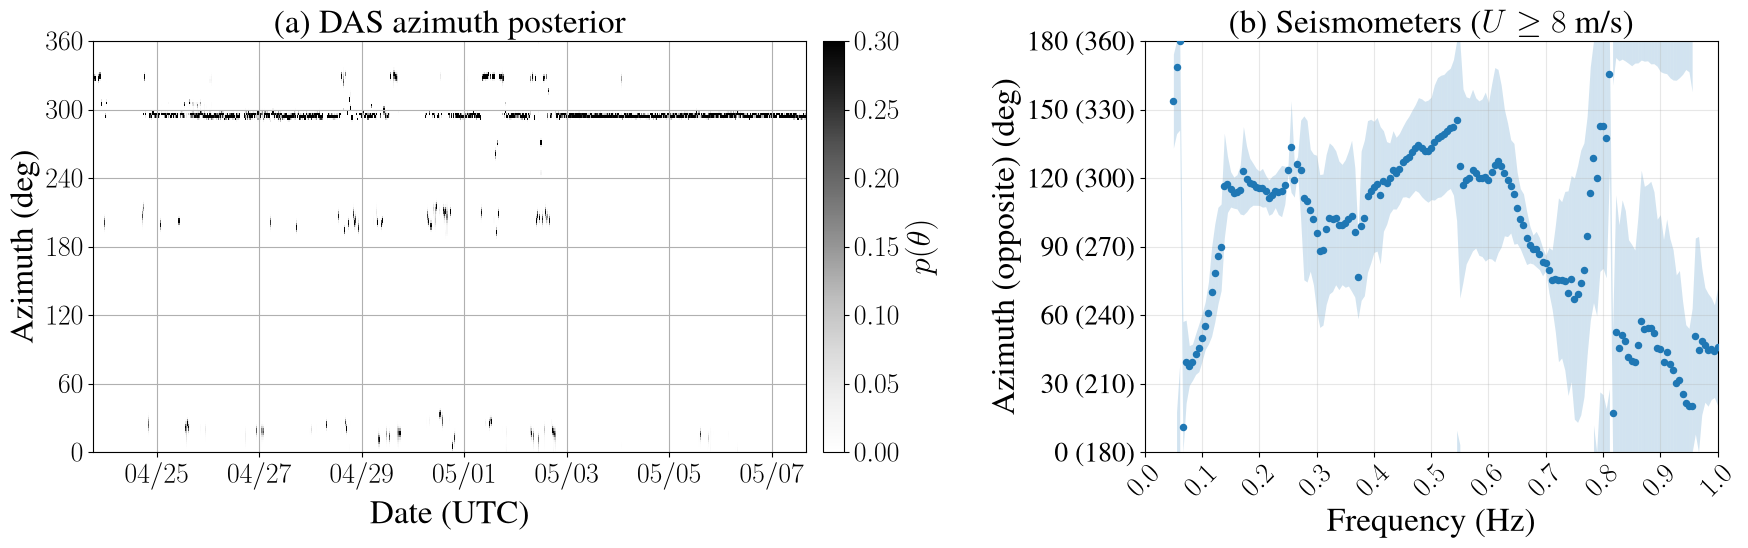

In [9]:
fig, axes = plt.subplots(
    1, 2,
    figsize=(18, 6.0),
    gridspec_kw={"width_ratios": [6, 4]},
)

plot_posterior_panel(axes[0], NPZ_PATH)
axes[0].set_title(r"(a) DAS azimuth posterior")

plot_combined_azimuth_panel(axes[1], result_comb)
axes[1].set_title(rf"(b) Seismometers ($U \geq {HIGH_WIND:g}$ m/s)")

fig.tight_layout()

fig.savefig(OUT_FILE, dpi=200, bbox_inches="tight")
print(f"wrote {OUT_FILE}")

plt.show()